In [2]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/competitions/flight-price-prediction/submission.csv
/kaggle/input/competitions/flight-price-prediction/train.csv
/kaggle/input/competitions/flight-price-prediction/test.csv


In [48]:
import os
import pandas as pd
import kagglehub
dataset_path = kagglehub.competition_download('flight-price-prediction')
sub_path = os.path.join(dataset_path, 'submission.csv')
sub_sample = pd.read_csv(sub_path)

In [3]:
train=pd.read_csv("/kaggle/input/competitions/flight-price-prediction/train.csv");
test=pd.read_csv("/kaggle/input/competitions/flight-price-prediction/test.csv");
print(train.shape)
print(test.shape)

(18076, 12)
(4520, 11)


In [4]:
train.head()

,id,airline,flight,source_city,departure_time,stops,arrival_time,destination_city,flight_class,duration,days_left,price
0,2856,Southwest,WN 3596,San Jose,Early_Morning,zero,Morning,Los Angeles,Economy,1.33,5,315
1,21812,Southwest,WN 1307,San Jose,Evening,zero,Evening,San Diego,Economy,1.58,40,149
2,476,United,UA 1763,San Diego,Afternoon,zero,Afternoon,San Francisco,Economy,1.77,2,129
3,21802,Southwest,WN 367,San Jose,Morning,zero,Morning,San Diego,Economy,1.58,40,94
4,5099,United,UA 2117,San Diego,Afternoon,zero,Evening,San Francisco,Economy,1.70,9,146


In [5]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 18076 entries, 0 to 18075
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   id                18076 non-null  int64  
 1   airline           18076 non-null  object 
 2   flight            18076 non-null  object 
 3   source_city       18076 non-null  object 
 4   departure_time    18076 non-null  object 
 5   stops             18076 non-null  object 
 6   arrival_time      18076 non-null  object 
 7   destination_city  18076 non-null  object 
 8   flight_class      18076 non-null  object 
 9   duration          18076 non-null  float64
 10  days_left         18076 non-null  int64  
 11  price             18076 non-null  int64  
dtypes: float64(1), int64(3), object(8)
memory usage: 1.7+ MB


In [6]:
train.describe()

,id,duration,days_left,price
count,18076.000000,18076.000000,18076.000000,18076.000000
mean,11308.626189,2.746853,20.520912,280.264550
std,6526.337957,2.947519,12.094984,221.965133
min,0.000000,0.870000,1.000000,0.000000
25%,5668.750000,1.470000,10.000000,157.000000
50%,11329.500000,1.630000,20.000000,234.000000
75%,16949.500000,2.000000,31.000000,336.000000
max,22595.000000,28.650000,44.000000,8996.000000


In [7]:
def missing_summary(df):
  missing = df.isna().sum()
  missing_pct = (missing/len(df))*100
  return pd.DataFrame({
      "missing_count" : missing,
      "missing_pct" : missing_pct.round(2)
  }).sort_values("missing_count", ascending = False)
print(missing_summary(train))

                  missing_count  missing_pct
id                            0          0.0
airline                       0          0.0
flight                        0          0.0
source_city                   0          0.0
departure_time                0          0.0
stops                         0          0.0
arrival_time                  0          0.0
destination_city              0          0.0
flight_class                  0          0.0
duration                      0          0.0
days_left                     0          0.0
price                         0          0.0


In [8]:
print(missing_summary(test))

                  missing_count  missing_pct
id                            0          0.0
airline                       0          0.0
flight                        0          0.0
source_city                   0          0.0
departure_time                0          0.0
stops                         0          0.0
arrival_time                  0          0.0
destination_city              0          0.0
flight_class                  0          0.0
duration                      0          0.0
days_left                     0          0.0


In [9]:
print("Duplicate rows:", train.duplicated().sum())

Duplicate rows: 0


In [10]:
#Observations
#The dataset contains no missing values, so no missing-value imputation is required.
#There are no duplicate rows, indicating that each record appears to be unique.
#Therefore, the dataset does not require additional cleaning for missing or duplicate observations.

In [11]:
num_cols = train.select_dtypes(include=np.number).columns
cat_cols = train.select_dtypes(include="object").columns
print("Numerical:", list(num_cols))
print("Categorical:", list(cat_cols))

Numerical: ['id', 'duration', 'days_left', 'price']
Categorical: ['airline', 'flight', 'source_city', 'departure_time', 'stops', 'arrival_time', 'destination_city', 'flight_class']


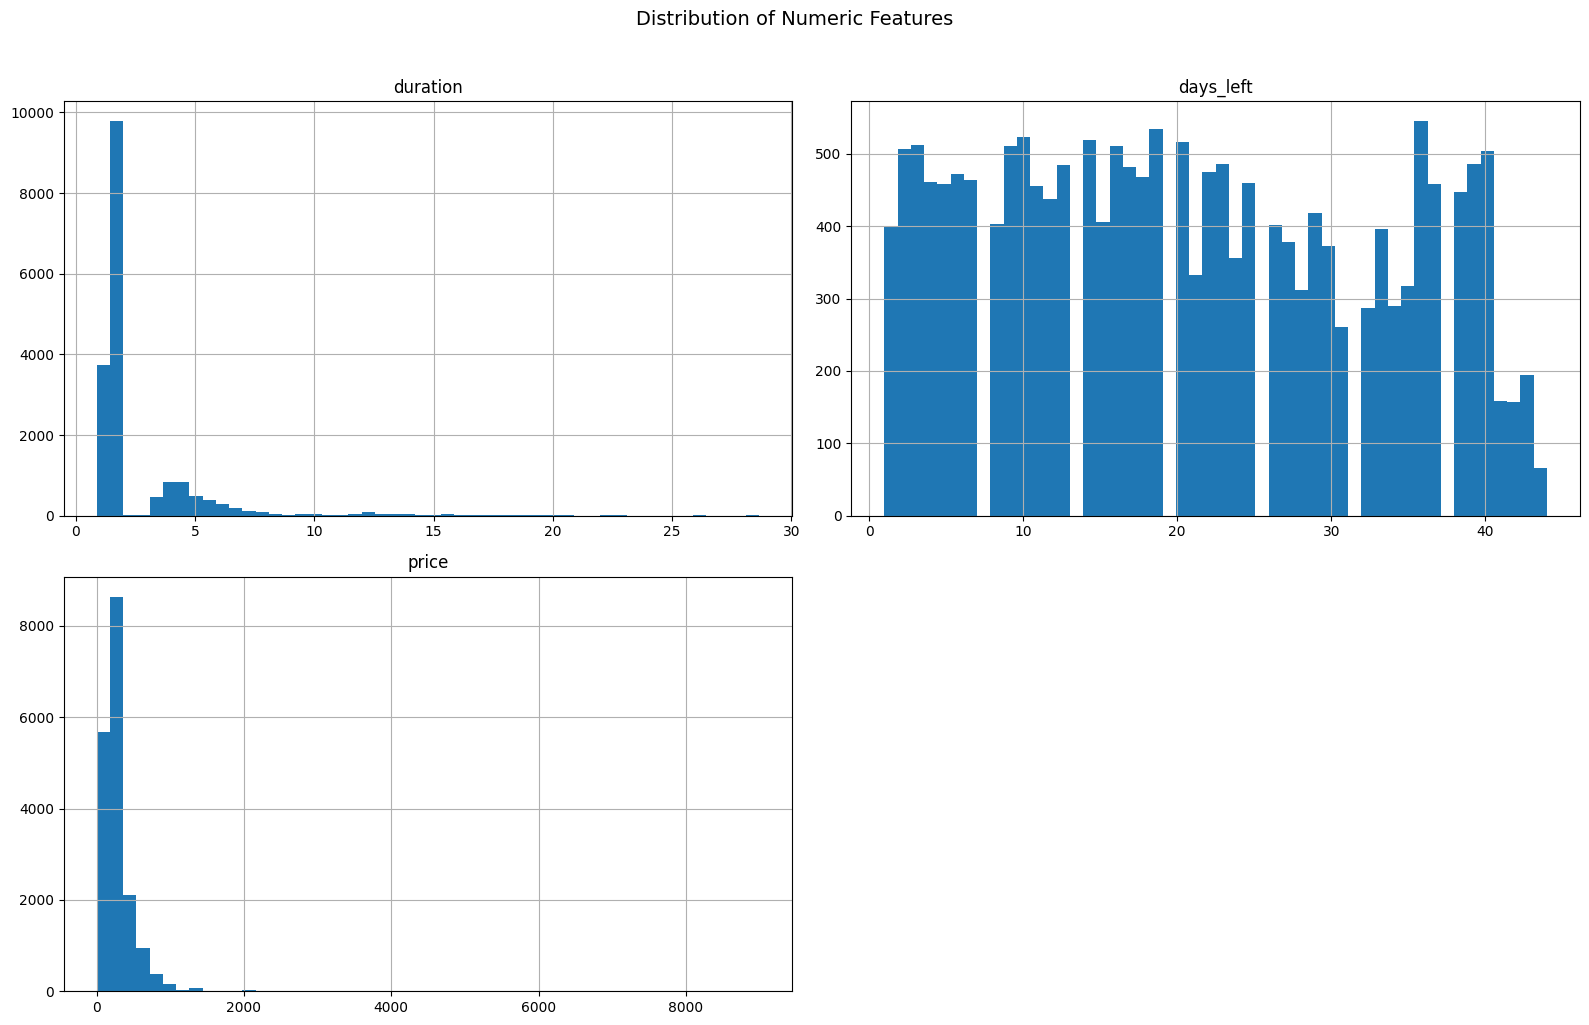

In [12]:
#Numerical feature distributions
#id is excluded from numerical feature analysis because it serves as a unique identifier
#and does not represent a meaningful numerical property of the flight.
import matplotlib.pyplot as plt
num_cols = ['duration', 'days_left', 'price']
train[num_cols].hist(bins=50, figsize=(16,10))
plt.suptitle("Distribution of Numeric Features", y=1.02, fontsize=14)
plt.tight_layout()
plt.show()

In [13]:
#Observation
#duration : The majority of values are concentrated at low numbers, heavily clustered around
#1 to 2 hours. (Strong Right-Skewed Distribution)
#days_left : The counts are fairly evenly distributed across the entire range from 1 to roughly 43 days.
#price : Most instances are concentrated at lower price points (primarily under 500 to 1,000 units), with the sharpest
#peak occurring around 200–400. (Heavily Right-Skewed Distribution)

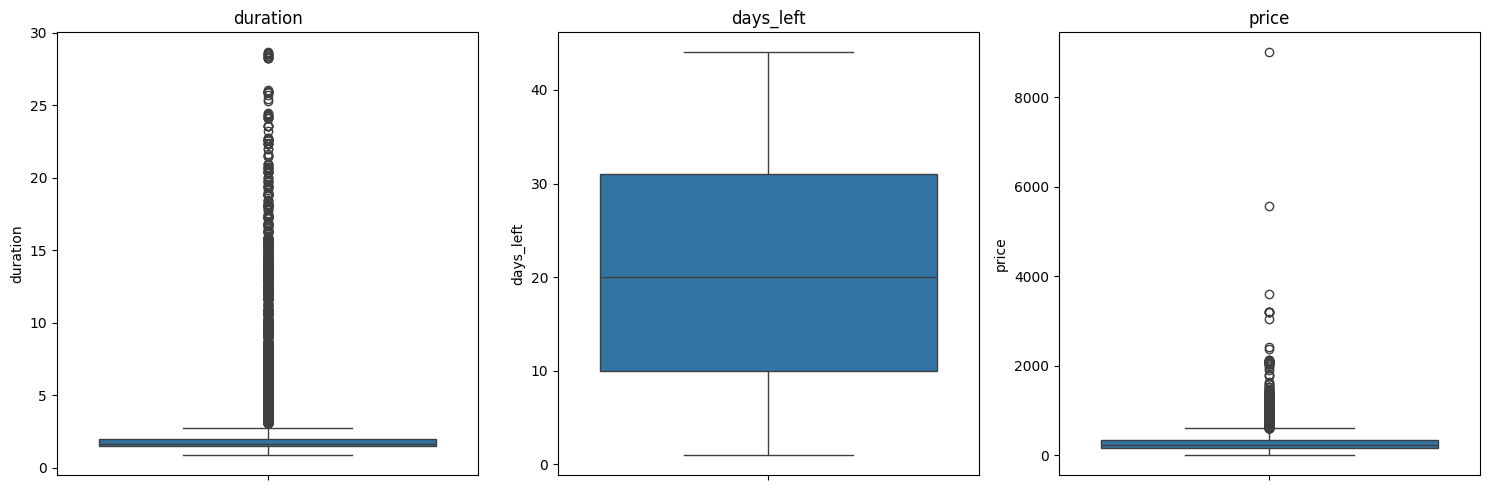

In [14]:
#Boxplots - Spotting outliers
import seaborn as sns
fig, axes = plt.subplots(1, 3, figsize=(15,5))
for i, col in enumerate(num_cols):
  sns.boxplot(y=train[col], ax=axes[i])
  axes[i].set_title(col)
plt.tight_layout()
plt.show()

In [15]:
#Categorical Feature Distribution
for col in cat_cols:
  print(f"\n{col}")
  print("Unique values:", train[col].unique())
  print(train[col].value_counts())


airline
Unique values: ['Southwest' 'United' 'American_Airlines' 'Alaska_Airlines' 'Delta'
 'Frontier' 'Southern_Airways_Express']
airline
Alaska_Airlines             4554
United                      4058
Southwest                   3895
Delta                       2972
American_Airlines           1797
Frontier                     799
Southern_Airways_Express       1
Name: count, dtype: int64

flight
Unique values: ['WN 3596' 'WN 1307' 'UA 1763' ... 'AA 2226' 'WN 3310' 'AS 3325']
flight
AA 6279    183
DL 3716    156
DL 3883    149
AA 1358    144
DL 4087    141
          ... 
UA 580       1
WN 4997      1
AA 2226      1
WN 3310      1
AS 3325      1
Name: count, Length: 1123, dtype: int64

source_city
Unique values: ['San Jose' 'San Diego' 'San Francisco' 'Los Angeles' 'Sacramento']
source_city
Los Angeles      4561
San Francisco    4086
San Diego        3691
Sacramento       3521
San Jose         2217
Name: count, dtype: int64

departure_time
Unique values: ['Early_Morning' 'Evening' 

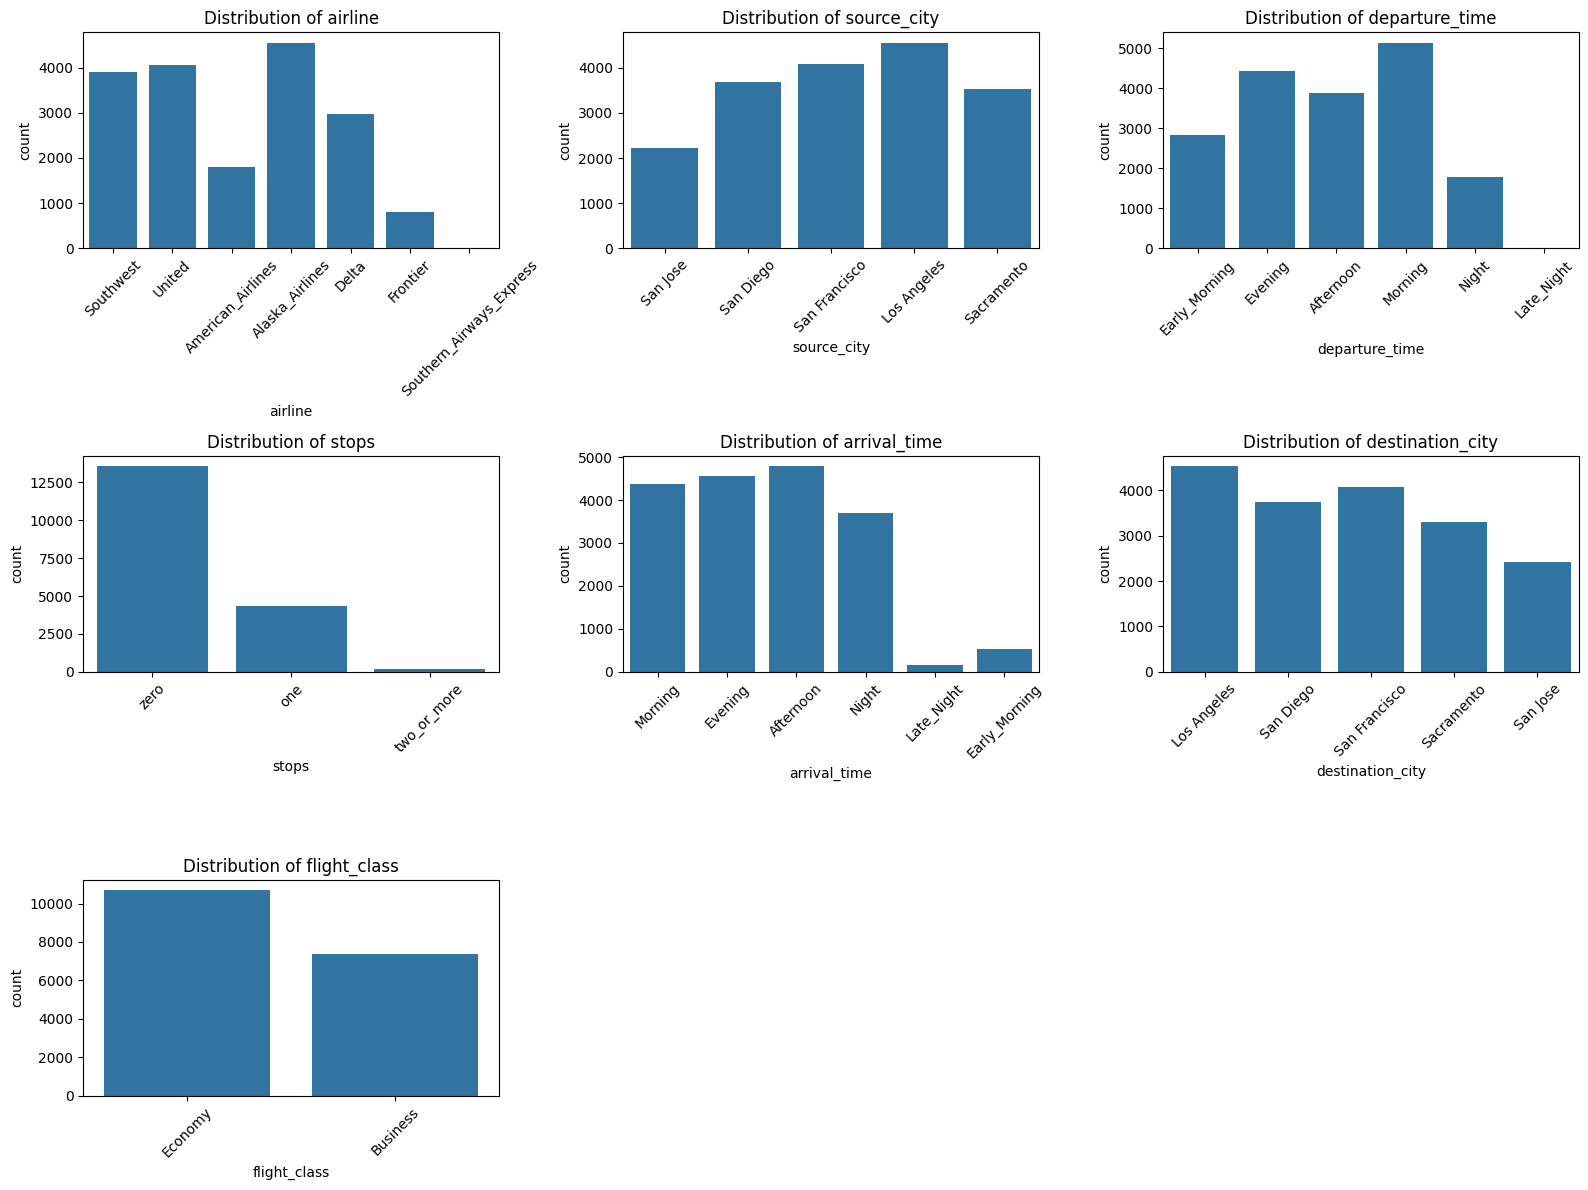

In [16]:
plot_cols = ['airline', 'source_city', 'departure_time', 'stops', 'arrival_time', 'destination_city', 'flight_class']
fig, axes = plt.subplots(3, 3, figsize=(16,12))
axes = axes.flatten()
for i, col in enumerate(plot_cols):
  sns.countplot(data=train, x=col, ax=axes[i])
  axes[i].set_title(f'Distribution of {col}')
  axes[i].tick_params(axis='x', rotation=45)
for j in range(len(plot_cols), len(axes)):
  fig.delaxes(axes[j])
plt.tight_layout()
plt.show()

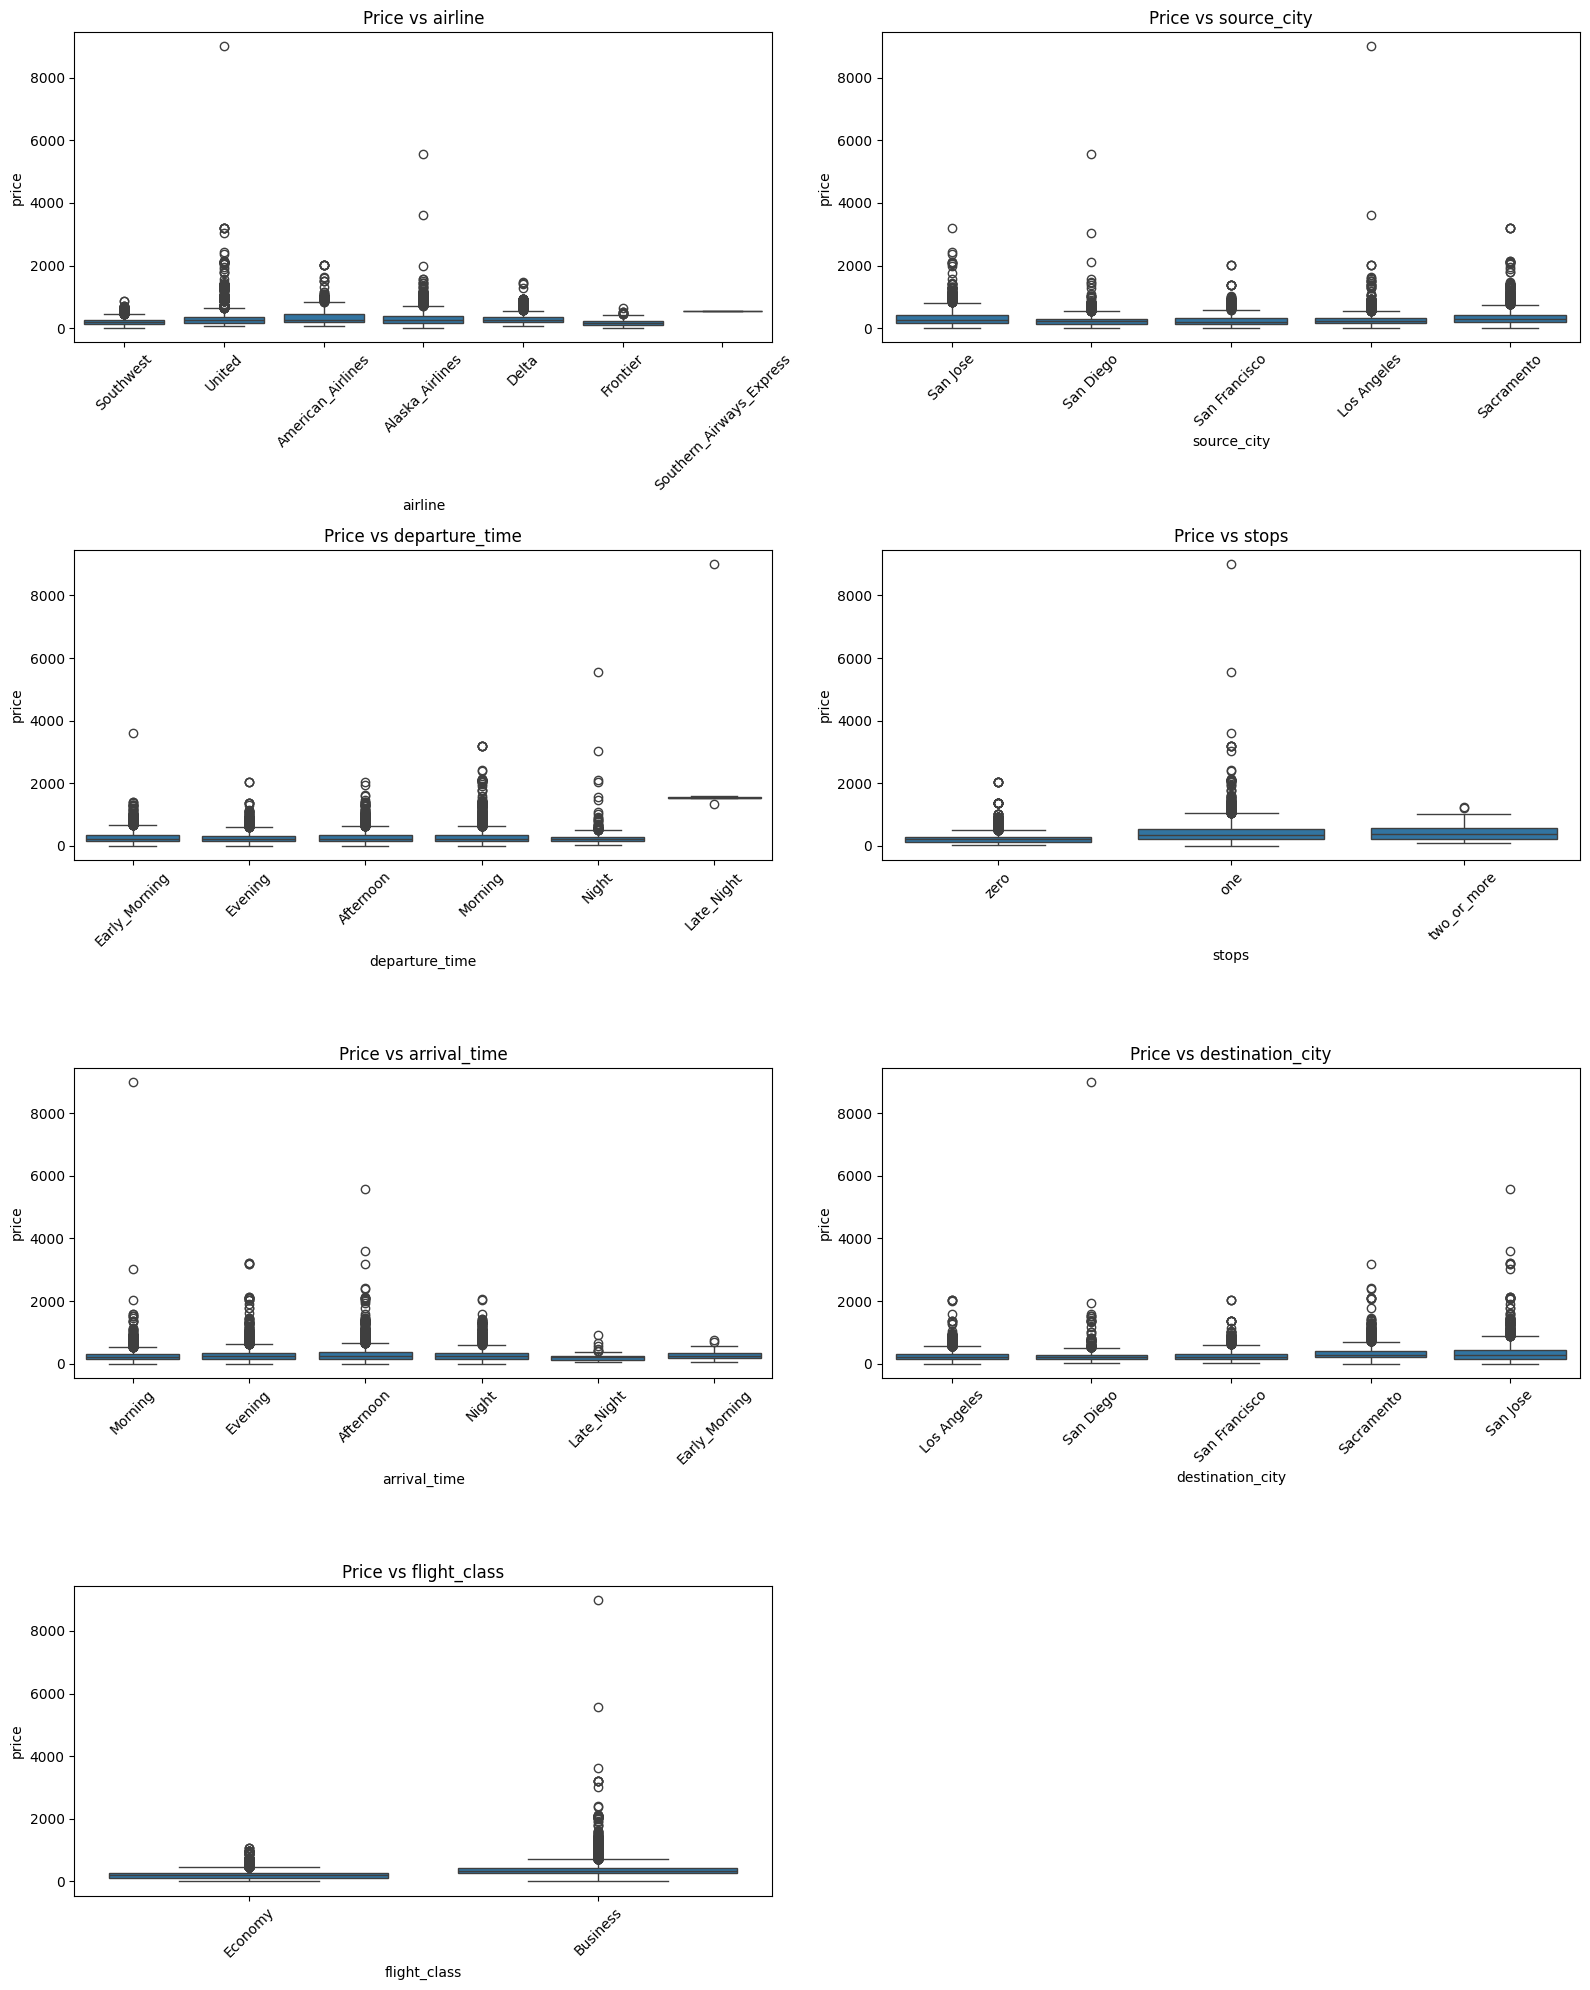

In [17]:
#Analyze categorical features vs price
fig, axes = plt.subplots(4, 2, figsize=(16,20))
axes = axes.flatten()
for i,col in enumerate(plot_cols):
  sns.boxplot(data=train, x=col, y='price', ax=axes[i])
  axes[i].set_title(f'Price vs {col}')
  axes[i].tick_params(axis='x', rotation=45)
for j in range(len(plot_cols), len(axes)):
  fig.delaxes(axes[j])
plt.tight_layout()
plt.show()

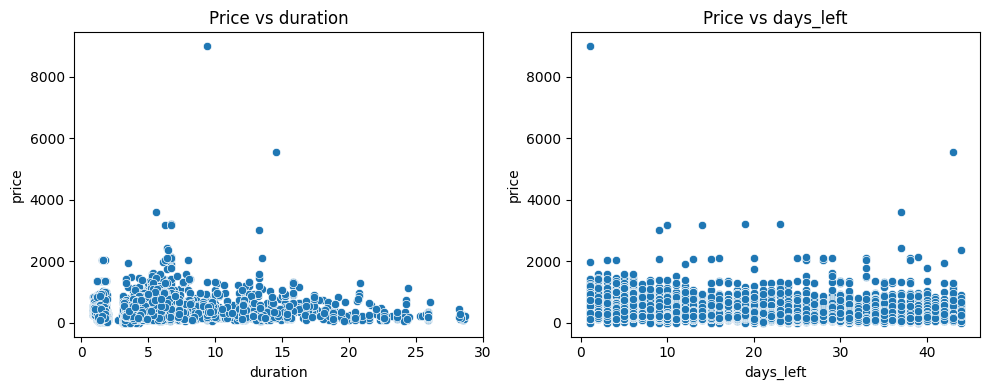

In [18]:
#Numerical features vs price
num_features = ['duration', 'days_left']
fig, axes = plt.subplots(1, 2, figsize=(10,4))
for i,col in enumerate(num_features):
  sns.scatterplot(data=train, x=col, y='price', ax=axes[i])
  axes[i].set_title(f'Price vs {col}')
plt.tight_layout()
plt.show()

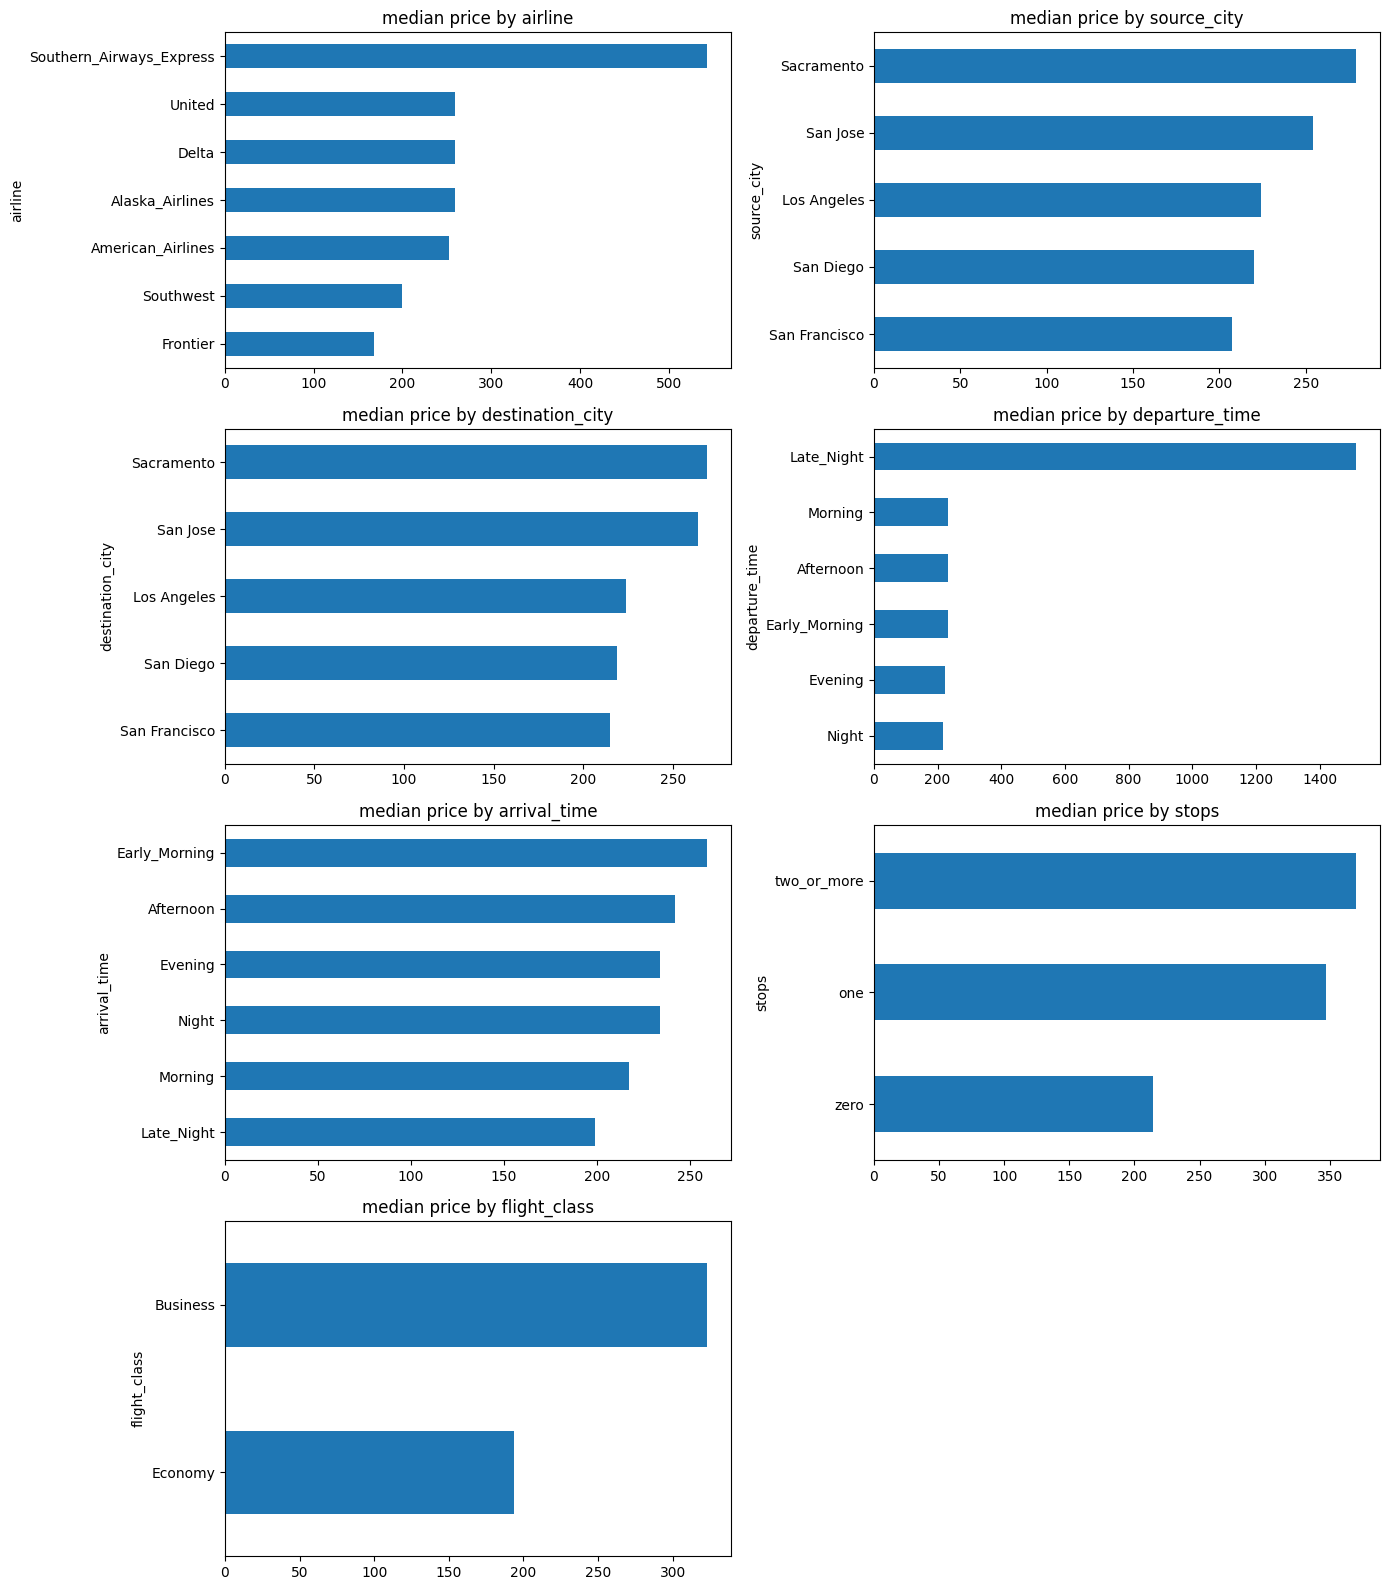

In [19]:
cats = ["airline", "source_city", "destination_city", "departure_time",
        "arrival_time", "stops", "flight_class"]
fig, axes = plt.subplots(4, 2, figsize=(14, 16))
for a, c in zip(axes.flat, cats):
    train.groupby(c).price.median().sort_values().plot(kind="barh", ax=a)
    a.set_title(f"median price by {c}")
axes.flat[-1].axis("off")
plt.tight_layout(); plt.show()

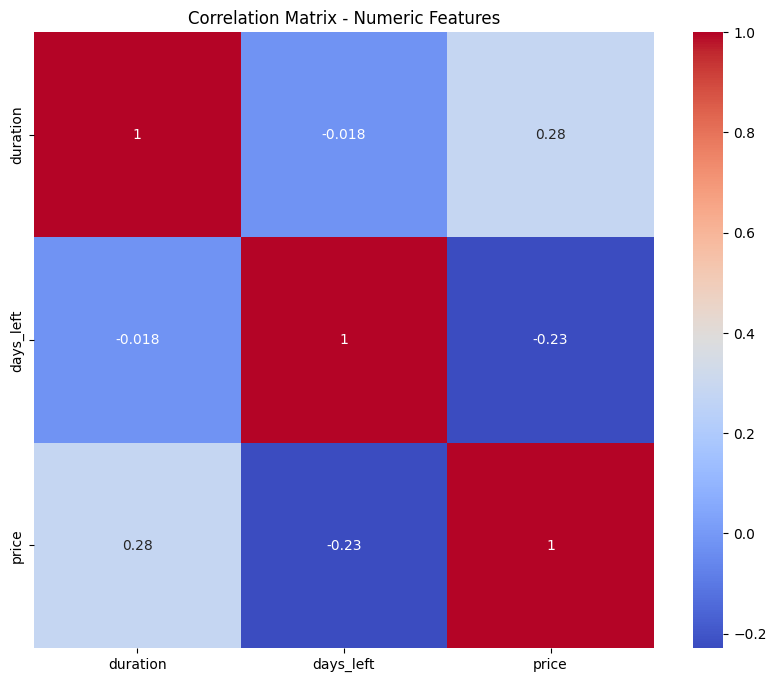

In [20]:
corr = train[['duration', 'days_left', 'price']].corr()
plt.figure(figsize=(10,8))
sns.heatmap(corr, annot=True, cmap="coolwarm")
plt.title("Correlation Matrix - Numeric Features")
plt.show()

In [21]:
# Correlation of every feature with the target, sorted
corr["price"].sort_values(ascending=False)

price        1.000000
duration     0.281357
days_left   -0.229164
Name: price, dtype: float64

In [22]:
#Observations
#duration has a positive correlation with price, suggesting that flight duration may influence ticket prices.
#days_left has a negative correlation with price, suggesting that prices tend to increase as the departure date approaches.
#Both correlations are relatively weak, indicating that other factors may also influence flight prices.

In [23]:
#Check skewness
print(train[num_cols].skew().sort_values(ascending=False))

price        7.069918
duration     3.875210
days_left    0.146296
dtype: float64


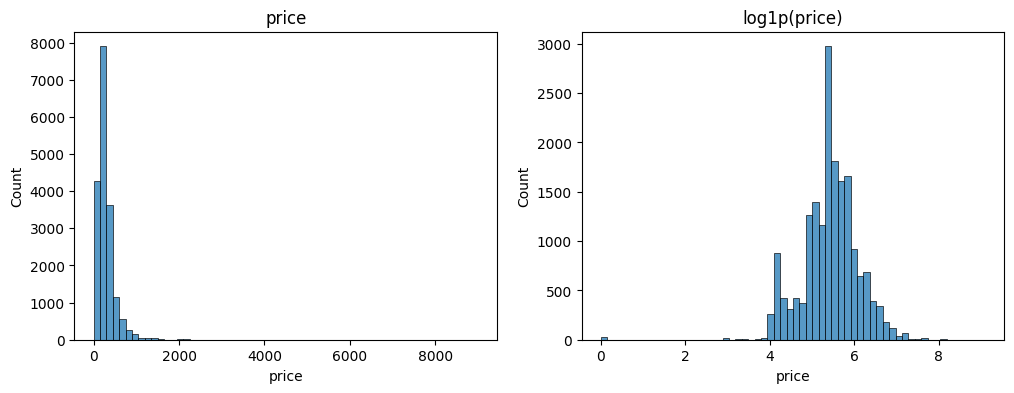

In [24]:
#Log transform price
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(train.price, bins=60, ax=ax[0]); ax[0].set_title("price")
sns.histplot(np.log1p(train.price), bins=60, ax=ax[1]); ax[1].set_title("log1p(price)")
plt.show()

In [25]:
#Outlier detection using IQR method
def iqr_outlier_bounds(series):
    q1, q3 = series.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

outlier_summary = {}
for col in num_cols:
    low, high = iqr_outlier_bounds(train[col])
    n_outliers = ((train[col] < low) | (train[col] > high)).sum()
    outlier_summary[col] = n_outliers

pd.Series(outlier_summary, name="num_outliers").sort_values(ascending=False)

duration     4516
price        1120
days_left       0
Name: num_outliers, dtype: int64

In [26]:
#Feature Engineering and Data Preprocessing
df = train[train.price > 0].copy()

def make_features(d):
    d = d.copy()
    d["route"] = d.source_city + "_" + d.destination_city
    d["stops_n"] = d.stops.map({"zero": 0, "one": 1, "two_or_more": 2})
    d["near"] = (d.days_left <= 14).astype(int)
    return d

df = make_features(df)
test_f = make_features(test)

cat_cols = ["airline", "source_city", "destination_city", "departure_time",
            "arrival_time", "stops", "flight_class", "route"]
all_X = pd.concat([df.drop(columns=["id", "price", "flight"]),
                   test_f.drop(columns=["id", "flight"])], keys=["tr", "te"])
all_X = pd.get_dummies(all_X, columns=cat_cols)

all_X["flight"] = pd.Categorical(pd.concat([df.flight, test_f.flight])).codes

X = all_X.loc["tr"]
X_test = all_X.loc["te"]
y = df.price.values
y_log = np.log1p(y)
print(X.shape, X_test.shape)

(18051, 57) (4520, 57)


In [27]:
from sklearn.model_selection import train_test_split
Xa, Xb, ya, yb = train_test_split(X, y_log, test_size=0.2, random_state=42)

In [28]:
#Linear Regression
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
from sklearn.linear_model import LinearRegression
lr_log = LinearRegression()
lr_log.fit(Xa, ya)
pred = np.expm1(lr_log.predict(Xb))
true = np.expm1(yb)
mse = mean_squared_error(true, pred)
rmse = np.sqrt(mse)
print(f"\n--- Linear Regression Model Evaluation ---")
print(f"Mean Squared Error (MSE) : {mse:.2f}")
print(f"Root Mean Squared Error (RMSE) : {rmse:.2f}")
print("R2 :", round(r2_score(true, pred), 3))
print("MAE:", round(mean_absolute_error(true, pred), 1))
print("within 20%:", round((abs(pred - true) / true < 0.2).mean(), 3))



--- Linear Regression Model Evaluation ---
Mean Squared Error (MSE) : 15689.69
Root Mean Squared Error (RMSE) : 125.26
R2 : 0.609
MAE: 71.9
within 20%: 0.467


In [29]:
# Polynomial Regression
from sklearn.preprocessing import PolynomialFeatures

# Numerical columns for polynomial expansion
poly_cols = [
    col for col in ["duration", "days_left", "stops_n", "near"]
    if col in X.columns
]

# Polynomial expansion
poly_features = PolynomialFeatures(
    degree=2,
    include_bias=False
)

Xa_poly = poly_features.fit_transform(Xa[poly_cols])
Xb_poly = poly_features.transform(Xb[poly_cols])

# Keep remaining preprocessed features unchanged
other_cols = [col for col in X.columns if col not in poly_cols]

Xa_final = np.hstack([Xa_poly, Xa[other_cols].values])
Xb_final = np.hstack([Xb_poly, Xb[other_cols].values])

# Train Polynomial Regression Model
poly_model = LinearRegression()
poly_model.fit(Xa_final, ya)

# Predictions on original price scale
pred = np.expm1(poly_model.predict(Xb_final))
true = np.expm1(yb)

# Evaluation
mse = mean_squared_error(true, pred)
rmse = np.sqrt(mse)

print("\n--- Polynomial Regression (Degree 2) Evaluation ---")
print(f"Mean Squared Error (MSE): {mse:.2f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.2f}")
print("R2 :", round(r2_score(true, pred), 3))
print("MAE:", round(mean_absolute_error(true, pred), 1))
print("within 20%:", round((abs(pred - true) / true < 0.2).mean(), 3))


--- Polynomial Regression (Degree 2) Evaluation ---
Mean Squared Error (MSE): 15634.39
Root Mean Squared Error (RMSE): 125.04
R2 : 0.611
MAE: 71.7
within 20%: 0.471


In [30]:
# Ridge Regression
from sklearn.linear_model import Ridge

for alpha in [0.1, 1.0, 10.0, 100.0]:

    ridge_model = Ridge(alpha=alpha)
    ridge_model.fit(Xa, ya)

    # Predictions on original price scale
    pred = np.expm1(ridge_model.predict(Xb))
    true = np.expm1(yb)

    mse = mean_squared_error(true, pred)
    rmse = np.sqrt(mse)

    print(f"\n--- Ridge Regression (Alpha = {alpha}) ---")
    print(f"Mean Squared Error (MSE): {mse:.2f}")
    print(f"Root Mean Squared Error (RMSE): {rmse:.2f}")
    print("R2 :", round(r2_score(true, pred), 3))
    print("MAE:", round(mean_absolute_error(true, pred), 1))
    print("within 20%:", round((abs(pred - true) / true < 0.2).mean(), 3))
    print("-" * 30)


--- Ridge Regression (Alpha = 0.1) ---
Mean Squared Error (MSE): 15690.58
Root Mean Squared Error (RMSE): 125.26
R2 : 0.609
MAE: 71.9
within 20%: 0.467
------------------------------

--- Ridge Regression (Alpha = 1.0) ---
Mean Squared Error (MSE): 15738.73
Root Mean Squared Error (RMSE): 125.45
R2 : 0.608
MAE: 72.0
within 20%: 0.467
------------------------------

--- Ridge Regression (Alpha = 10.0) ---
Mean Squared Error (MSE): 16084.19
Root Mean Squared Error (RMSE): 126.82
R2 : 0.6
MAE: 72.3
within 20%: 0.467
------------------------------

--- Ridge Regression (Alpha = 100.0) ---
Mean Squared Error (MSE): 16228.08
Root Mean Squared Error (RMSE): 127.39
R2 : 0.596
MAE: 72.3
within 20%: 0.464
------------------------------


In [34]:
from sklearn.ensemble import RandomForestRegressor
rf = RandomForestRegressor(n_estimators=300, n_jobs=-1, random_state=42)
rf.fit(Xa, ya)

pred = np.expm1(rf.predict(Xb))
true = np.expm1(yb)
print("R2 :", round(r2_score(true, pred), 3))
print("MAE:", round(mean_absolute_error(true, pred), 1))
print("within 20%:", round((abs(pred - true) / true < 0.2).mean(), 3))

R2 : 0.778
MAE: 38.4
within 20%: 0.787


In [38]:
#5-fold cross validation on Random Forest Model
from sklearn.model_selection import KFold
kf = KFold(n_splits=5, shuffle=True, random_state=42)
r2s, within = [], []
for tr_idx, va_idx in kf.split(X):
    m = RandomForestRegressor(n_estimators=300, n_jobs=-1, random_state=42)
    m.fit(X.iloc[tr_idx], y_log[tr_idx])
    p = np.expm1(m.predict(X.iloc[va_idx]))
    t = np.expm1(y_log[va_idx])
    r2s.append(r2_score(t, p))
    within.append((abs(p - t) / t < 0.2).mean())

print("R2 per fold:", np.round(r2s, 3), "mean:", round(np.mean(r2s), 3))
print("within 20% per fold:", np.round(within, 3), "mean:", round(np.mean(within), 3))

R2 per fold: [0.778 0.675 0.546 0.737 0.762] mean: 0.7
within 20% per fold: [0.789 0.788 0.775 0.773 0.776] mean: 0.78


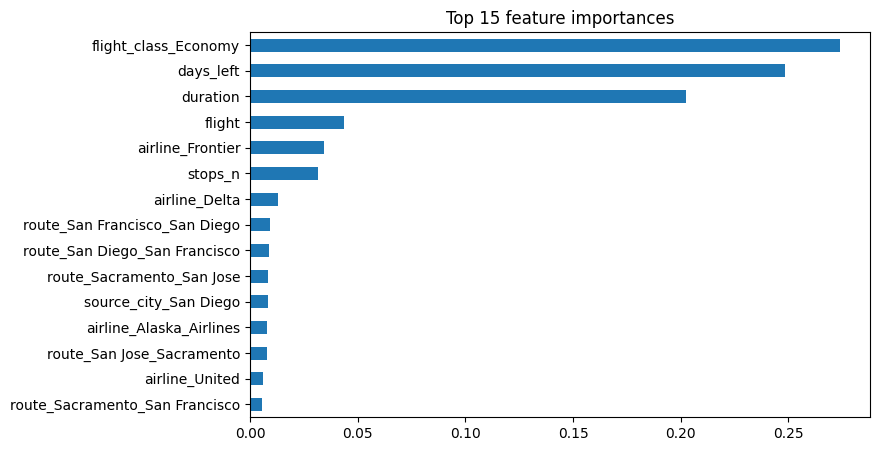

In [39]:
#Plot the 15 most important features in Random Forest Model
imp = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)
imp.head(15).plot(kind="barh", figsize=(8, 5)).invert_yaxis()
plt.title("Top 15 feature importances"); plt.show()

In [42]:
#Hyperparameter tuning on Random Forest Model
import time
from sklearn.model_selection import RandomizedSearchCV
params = {
    "n_estimators": [150, 250],
    "max_depth": [20, 30, None],
    "min_samples_leaf": [1, 2],
    "max_features": [0.3, 0.5],
}
t0 = time.time()
search = RandomizedSearchCV(
    RandomForestRegressor(n_jobs=-1, random_state=42),
    params, n_iter=8, cv=3, scoring="r2", random_state=42, n_jobs=1, verbose=2)
search.fit(X, y_log)
print(search.best_params_, round(search.best_score_, 3))
print("time (min):", round((time.time() - t0) / 60, 1))

Fitting 3 folds for each of 8 candidates, totalling 24 fits
[CV] END max_depth=30, max_features=0.3, min_samples_leaf=1, n_estimators=150; total time=   2.0s
[CV] END max_depth=30, max_features=0.3, min_samples_leaf=1, n_estimators=150; total time=   2.2s
[CV] END max_depth=30, max_features=0.3, min_samples_leaf=1, n_estimators=150; total time=   2.1s
[CV] END max_depth=None, max_features=0.3, min_samples_leaf=1, n_estimators=150; total time=   2.1s
[CV] END max_depth=None, max_features=0.3, min_samples_leaf=1, n_estimators=150; total time=   2.1s
[CV] END max_depth=None, max_features=0.3, min_samples_leaf=1, n_estimators=150; total time=   2.1s
[CV] END max_depth=20, max_features=0.3, min_samples_leaf=1, n_estimators=150; total time=   2.1s
[CV] END max_depth=20, max_features=0.3, min_samples_leaf=1, n_estimators=150; total time=   2.1s
[CV] END max_depth=20, max_features=0.3, min_samples_leaf=1, n_estimators=150; total time=   2.4s
[CV] END max_depth=None, max_features=0.3, min_sampl

In [43]:
params = {
    "n_estimators": [250, 400],
    "max_depth": [30, 40, None],
    "min_samples_leaf": [1],
    "max_features": [0.5, 0.6, 0.7, 0.8],
}
t0 = time.time()
search2 = RandomizedSearchCV(
    RandomForestRegressor(n_jobs=-1, random_state=42),
    params, n_iter=10, cv=3, scoring="r2", random_state=42, n_jobs=1, verbose=1)
search2.fit(X, y_log)
print(search2.best_params_, round(search2.best_score_, 3))
print("time (min):", round((time.time() - t0) / 60, 1))

Fitting 3 folds for each of 10 candidates, totalling 30 fits
{'n_estimators': 400, 'min_samples_leaf': 1, 'max_features': 0.7, 'max_depth': 40} 0.868
time (min): 3.7


In [45]:
best_params = search2.best_params_ if search2.best_score_ > search.best_score_ else search.best_params_
print("using:", best_params)

kf = KFold(n_splits=5, shuffle=True, random_state=42)
r2s, within = [], []
for tr_idx, va_idx in kf.split(X):
    m = RandomForestRegressor(**best_params, n_jobs=-1, random_state=42)
    m.fit(X.iloc[tr_idx], y_log[tr_idx])
    p = np.expm1(m.predict(X.iloc[va_idx]))
    t = np.expm1(y_log[va_idx])
    r2s.append(r2_score(t, p))
    within.append((abs(p - t) / t < 0.2).mean())

print("R2 per fold:", np.round(r2s, 3), "mean:", round(np.mean(r2s), 3))
print("within 20% per fold:", np.round(within, 3), "mean:", round(np.mean(within), 3))

using: {'n_estimators': 400, 'min_samples_leaf': 1, 'max_features': 0.7, 'max_depth': 40}
R2 per fold: [0.773 0.673 0.543 0.74  0.768] mean: 0.699
within 20% per fold: [0.783 0.781 0.776 0.773 0.778] mean: 0.778


In [49]:
#Training the best Random Forest Model on the full training dataset and generating submission.csv
best = RandomForestRegressor(**best_params, n_jobs=-1, random_state=42)
best.fit(X, y_log)

sub = sub_sample.copy()
sub["price"] = np.expm1(best.predict(X_test)).round().astype(int)
sub = sub[["id", "price"]]
assert (sub.id.values == test.id.values).all()
sub.to_csv("submission_rf.csv", index=False)
sub.head()

,id,price
0,18395,61
1,11771,159
2,22326,348
3,18332,140
4,11021,556


In [51]:
#Comparing Model Performance With and Without Expensive Flights
def cv_eval(train_mask=None):
    res = []
    for tr_idx, va_idx in kf.split(X):
        if train_mask is not None:
            tr_idx = tr_idx[train_mask[tr_idx]]
        m = RandomForestRegressor(**best_params, n_jobs=-1, random_state=42)
        m.fit(X.iloc[tr_idx], y_log[tr_idx])
        p = np.expm1(m.predict(X.iloc[va_idx])); t = np.expm1(y_log[va_idx])
        keep = t <= 2500
        res.append((r2_score(t, p), r2_score(t[keep], p[keep]), (abs(p - t) / t < 0.2).mean()))
    return np.round(np.mean(res, axis=0), 3)

print("[full R2, R2 excl. >2500 rows, within 20%]")
print("baseline            :", cv_eval())
print("train without >2500 :", cv_eval(train_mask=(y <= 2500)))

[full R2, R2 excl. >2500 rows, within 20%]
baseline            : [0.699 0.768 0.778]
train without >2500 : [0.702 0.772 0.778]


In [53]:
#Target encoding for Flight and Flight Class
key = (df.flight + "|" + df.flight_class).values

def te_map(keys_fit, y_fit, keys_apply, prior, k=3):
    s = pd.DataFrame({"k": keys_fit, "y": y_fit}).groupby("k").y.agg(["sum", "count"])
    sm = (s["sum"] + prior * k) / (s["count"] + k)       # smoothed mean
    return pd.Series(keys_apply).map(sm).fillna(prior).values

r2s, within = [], []
for tr_idx, va_idx in kf.split(X):
    prior = y_log[tr_idx].mean()
    # inner out-of-fold encoding for training rows (prevents leakage)
    te_tr = np.zeros(len(tr_idx))
    for a, b in KFold(5, shuffle=True, random_state=42).split(tr_idx):
        te_tr[b] = te_map(key[tr_idx][a], y_log[tr_idx][a], key[tr_idx][b], prior)
    te_va = te_map(key[tr_idx], y_log[tr_idx], key[va_idx], prior)

    Xtr = X.iloc[tr_idx].assign(flight_te=te_tr)
    Xva = X.iloc[va_idx].assign(flight_te=te_va)

    m = RandomForestRegressor(**best_params, n_jobs=-1, random_state=42)
    m.fit(Xtr, y_log[tr_idx])
    p = np.expm1(m.predict(Xva)); t = np.expm1(y_log[va_idx])
    r2s.append(r2_score(t, p)); within.append((abs(p - t) / t < 0.2).mean())

print("R2 per fold:", np.round(r2s, 3), "mean:", round(np.mean(r2s), 3))
print("within 20% per fold:", np.round(within, 3), "mean:", round(np.mean(within), 3))

R2 per fold: [0.772 0.664 0.521 0.759 0.761] mean: 0.695
within 20% per fold: [0.759 0.761 0.757 0.748 0.758] mean: 0.757


In [54]:
#Compare 5 regression models and 2 blended models
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import ExtraTreesRegressor, HistGradientBoostingRegressor

models = {
    "Linear regression": LinearRegression(),
    "Decision tree (depth 15)": DecisionTreeRegressor(max_depth=15, min_samples_leaf=2, random_state=42),
    "Extra trees": ExtraTreesRegressor(n_estimators=300, max_features=0.7, n_jobs=-1, random_state=42),
    "Random forest (tuned)": RandomForestRegressor(**best_params, n_jobs=-1, random_state=42),
    "Hist gradient boosting": HistGradientBoostingRegressor(max_iter=400, learning_rate=0.08,
                                                            max_leaf_nodes=63, random_state=42),
}

oof_preds = {}
for name, mdl in models.items():
    oof = np.zeros(len(X))
    for tr_idx, va_idx in kf.split(X):
        mdl.fit(X.iloc[tr_idx], y_log[tr_idx])
        oof[va_idx] = mdl.predict(X.iloc[va_idx])
    oof_preds[name] = oof

def report(name, log_pred):
    p, t = np.expm1(log_pred), y
    return {"model": name,
            "R2": round(r2_score(t, p), 3),
            "MAE": round(mean_absolute_error(t, p), 1),
            "within20%": round((abs(p - t) / t < 0.2).mean(), 3)}

rows = [report(n, o) for n, o in oof_preds.items()]
rows.append(report("Blend: RF + HistGB",
                   (oof_preds["Random forest (tuned)"] + oof_preds["Hist gradient boosting"]) / 2))
rows.append(report("Blend: RF + ExtraTrees",
                   (oof_preds["Random forest (tuned)"] + oof_preds["Extra trees"]) / 2))
pd.DataFrame(rows).sort_values("within20%", ascending=False)

,model,R2,MAE,within20%
5,Blend: RF + HistGB,0.698,39.4,0.791
4,Hist gradient boosting,0.700,40.6,0.787
3,Random forest (tuned),0.679,40.5,0.778
6,Blend: RF + ExtraTrees,0.663,41.7,0.773
2,Extra trees,0.620,44.2,0.762
1,Decision tree (depth 15),0.620,46.6,0.745
0,Linear regression,0.534,73.2,0.472


In [56]:
#hyperparameter tuning for Decision Tree and Extra Trees models
from sklearn.model_selection import GridSearchCV

# Decision tree
dt_search = GridSearchCV(
    DecisionTreeRegressor(random_state=42),
    {"max_depth": [10, 15, 20, 30, None], "min_samples_leaf": [1, 2, 4, 8]},
    cv=3, scoring="r2", n_jobs=-1, verbose=1)
dt_search.fit(X, y_log)
print("DT best:", dt_search.best_params_, round(dt_search.best_score_, 3))

# Extra trees
et_search = RandomizedSearchCV(
    ExtraTreesRegressor(n_jobs=-1, random_state=42),
    {"n_estimators": [200, 300, 400],
     "max_depth": [30, 40, None],
     "min_samples_leaf": [1, 2],
     "max_features": [0.5, 0.7, 0.9, 1.0]},
    n_iter=8, cv=3, scoring="r2", random_state=42, n_jobs=1, verbose=1)
et_search.fit(X, y_log)
print("ET best:", et_search.best_params_, round(et_search.best_score_, 3))

Fitting 3 folds for each of 20 candidates, totalling 60 fits
DT best: {'max_depth': 20, 'min_samples_leaf': 8} 0.837
Fitting 3 folds for each of 8 candidates, totalling 24 fits
ET best: {'n_estimators': 300, 'min_samples_leaf': 2, 'max_features': 0.7, 'max_depth': 30} 0.863


In [59]:
final_models = {
    "Linear regression": LinearRegression(),
    "Decision tree (tuned)": DecisionTreeRegressor(**dt_search.best_params_, random_state=42),
    "Extra trees (tuned)": ExtraTreesRegressor(**et_search.best_params_, n_jobs=-1, random_state=42),
    "Random forest (tuned)": RandomForestRegressor(**best_params, n_jobs=-1, random_state=42),
}

rows = []
for name, mdl in final_models.items():
    oof = np.zeros(len(X))
    for tr_idx, va_idx in kf.split(X):
        mdl.fit(X.iloc[tr_idx], y_log[tr_idx])
        oof[va_idx] = mdl.predict(X.iloc[va_idx])
    p = np.expm1(oof)
    rows.append({"model": name,
                 "R2": round(r2_score(y, p), 3),
                 "MAE": round(mean_absolute_error(y, p), 1),
                 "within20% (accuracy)": round((abs(p - y) / y < 0.2).mean(), 3)})

pd.DataFrame(rows).sort_values("within20% (accuracy)", ascending=False)

,model,R2,MAE,within20% (accuracy)
3,Random forest (tuned),0.679,40.5,0.778
2,Extra trees (tuned),0.690,41.7,0.768
1,Decision tree (tuned),0.644,46.5,0.737
0,Linear regression,0.534,73.2,0.472


In [60]:
#hyperparameter tuning for HistGradientBoostingRegressor (HGB)
import time
from sklearn.ensemble import HistGradientBoostingRegressor

t0 = time.time()
hgb_search = RandomizedSearchCV(
    HistGradientBoostingRegressor(random_state=42),
    {"max_iter": [300, 500, 800],
     "learning_rate": [0.03, 0.05, 0.08, 0.12],
     "max_leaf_nodes": [31, 63, 127],
     "min_samples_leaf": [10, 20, 40],
     "l2_regularization": [0.0, 1.0, 5.0]},
    n_iter=10, cv=3, scoring="r2", random_state=42, n_jobs=1, verbose=2)
hgb_search.fit(X, y_log)
print("HGB best:", hgb_search.best_params_, round(hgb_search.best_score_, 3))
print("time (min):", round((time.time() - t0) / 60, 1))

Fitting 3 folds for each of 10 candidates, totalling 30 fits
[CV] END l2_regularization=1.0, learning_rate=0.03, max_iter=800, max_leaf_nodes=127, min_samples_leaf=10; total time=   6.5s
[CV] END l2_regularization=1.0, learning_rate=0.03, max_iter=800, max_leaf_nodes=127, min_samples_leaf=10; total time=   8.1s
[CV] END l2_regularization=1.0, learning_rate=0.03, max_iter=800, max_leaf_nodes=127, min_samples_leaf=10; total time=   7.8s
[CV] END l2_regularization=1.0, learning_rate=0.03, max_iter=300, max_leaf_nodes=31, min_samples_leaf=10; total time=   2.4s
[CV] END l2_regularization=1.0, learning_rate=0.03, max_iter=300, max_leaf_nodes=31, min_samples_leaf=10; total time=   2.5s
[CV] END l2_regularization=1.0, learning_rate=0.03, max_iter=300, max_leaf_nodes=31, min_samples_leaf=10; total time=   2.6s
[CV] END l2_regularization=1.0, learning_rate=0.05, max_iter=300, max_leaf_nodes=31, min_samples_leaf=40; total time=   2.1s
[CV] END l2_regularization=1.0, learning_rate=0.05, max_iter=

In [62]:
#Compare tuned Random Forest, tuned Hist Gradient Boosting, and three blended models
hgb_params = hgb_search.best_params_

oof_rf = np.zeros(len(X)); oof_hgb = np.zeros(len(X))
for tr_idx, va_idx in kf.split(X):
    rfm = RandomForestRegressor(**best_params, n_jobs=-1, random_state=42).fit(X.iloc[tr_idx], y_log[tr_idx])
    hgm = HistGradientBoostingRegressor(**hgb_params, random_state=42).fit(X.iloc[tr_idx], y_log[tr_idx])
    oof_rf[va_idx] = rfm.predict(X.iloc[va_idx])
    oof_hgb[va_idx] = hgm.predict(X.iloc[va_idx])

def report(name, lp):
    p = np.expm1(lp)
    return {"model": name, "R2": round(r2_score(y, p), 3),
            "MAE": round(mean_absolute_error(y, p), 1),
            "within20% (accuracy)": round((abs(p - y) / y < 0.2).mean(), 3)}

rows = [report("Gradient boosting (tuned)", oof_hgb),
        report("Random forest (tuned)", oof_rf)]
for w in [0.3, 0.5, 0.7]:
    rows.append(report(f"Blend: {w:.1f} HGB + {1-w:.1f} RF", w * oof_hgb + (1 - w) * oof_rf))
pd.DataFrame(rows).sort_values("within20% (accuracy)", ascending=False)

,model,R2,MAE,within20% (accuracy)
0,Gradient boosting (tuned),0.700,39.9,0.792
4,Blend: 0.7 HGB + 0.3 RF,0.700,39.3,0.792
3,Blend: 0.5 HGB + 0.5 RF,0.697,39.2,0.792
2,Blend: 0.3 HGB + 0.7 RF,0.692,39.5,0.786
1,Random forest (tuned),0.679,40.5,0.778


In [65]:
W = 0.5   # weight on gradient boosting

rf_final = RandomForestRegressor(**best_params, n_jobs=-1, random_state=42).fit(X, y_log)
hgb_final = HistGradientBoostingRegressor(**hgb_params, random_state=42).fit(X, y_log)

log_pred = W * hgb_final.predict(X_test) + (1 - W) * rf_final.predict(X_test)

sub = sub_sample.copy()
sub["price"] = np.expm1(log_pred).round().astype(int)
sub = sub[["id", "price"]]
assert (sub.id.values == test.id.values).all()
sub.to_csv("submission_blend.csv", index=False)
sub.head()

,id,price
0,18395,60
1,11771,165
2,22326,353
3,18332,139
4,11021,519


In [66]:
chk = pd.read_csv("/kaggle/working/submission_blend.csv")
print(chk.shape, chk.columns.tolist(), chk.price.min(), chk.price.max())
print(chk.id.equals(test.id))

(4520, 2) ['id', 'price'] 25 2284
True


In [72]:
cat_feats = ["airline", "source_city", "destination_city", "departure_time",
             "arrival_time", "stops", "flight_class", "route"]
num_feats = ["duration", "days_left", "stops_n", "near"]

all_c = pd.concat([df[cat_feats + num_feats], test_f[cat_feats + num_feats]], keys=["tr", "te"])
for c in cat_feats:
    all_c[c] = all_c[c].astype("category")
all_c["flight"] = pd.Categorical(pd.concat([df.flight, test_f.flight])).codes

Xc = all_c.loc["tr"].reset_index(drop=True)
Xc_test = all_c.loc["te"].reset_index(drop=True)

hgb_cat = HistGradientBoostingRegressor(
    **hgb_params, categorical_features="from_dtype", random_state=42)

oof_cat = np.zeros(len(Xc))
for tr_idx, va_idx in kf.split(Xc):
    hgb_cat.fit(Xc.iloc[tr_idx], y_log[tr_idx])
    oof_cat[va_idx] = hgb_cat.predict(Xc.iloc[va_idx])

rows = [report("HGB native categories", oof_cat),
        report("HGB one-hot (current)", oof_hgb),
        report("Blend: HGB cat + HGB one-hot + RF", (oof_cat + oof_hgb + oof_rf) / 3),
        report("Blend: HGB cat + RF", (oof_cat + oof_rf) / 2)]
pd.DataFrame(rows).sort_values("within20% (accuracy)", ascending=False)

,model,R2,MAE,within20% (accuracy)
0,HGB native categories,0.708,38.9,0.798
2,Blend: HGB cat + HGB one-hot + RF,0.703,38.6,0.798
3,Blend: HGB cat + RF,0.701,38.6,0.794
1,HGB one-hot (current),0.700,39.9,0.792


In [74]:
#Final Submission Using Three-Model Blending
hgb_cat_final = HistGradientBoostingRegressor(
    **hgb_params, categorical_features="from_dtype", random_state=42).fit(Xc, y_log)

log_pred = (hgb_cat_final.predict(Xc_test)
            + hgb_final.predict(X_test)
            + rf_final.predict(X_test)) / 3

sub = sub_sample.copy()
sub["price"] = np.expm1(log_pred).round().astype(int)
sub = sub[["id", "price"]]
assert (sub.id.values == test.id.values).all()
sub.to_csv("submission_blend3.csv", index=False)
print(sub.shape, sub.price.min(), sub.price.max())
sub.head()

(4520, 2) 25 2211


,id,price
0,18395,59
1,11771,164
2,22326,358
3,18332,138
4,11021,519


In [75]:
#Best Hyperparameters for Hist Gradient Boosting
print(hgb_search.best_params_)

{'min_samples_leaf': 10, 'max_leaf_nodes': 127, 'max_iter': 800, 'learning_rate': 0.03, 'l2_regularization': 1.0}


In [70]:
def cv_hgb(params, X_, loss):
    oof = np.zeros(len(X_))
    for tr_idx, va_idx in kf.split(X_):
        m = HistGradientBoostingRegressor(**params, loss=loss,
                                          categorical_features="from_dtype", random_state=42)
        m.fit(X_.iloc[tr_idx], y_log[tr_idx])
        oof[va_idx] = m.predict(X_.iloc[va_idx])
    return oof

oof_abs = cv_hgb(hgb_params, Xc, "absolute_error")

rows = [report("HGB cat, squared error (current)", oof_cat),
        report("HGB cat, absolute error", oof_abs),
        report("Blend: abs + sq + RF", (oof_abs + oof_cat + oof_rf) / 3),
        report("Blend: abs + sq + onehot + RF", (oof_abs + oof_cat + oof_hgb + oof_rf) / 4)]
pd.DataFrame(rows).sort_values("within20% (accuracy)", ascending=False)

,model,R2,MAE,within20% (accuracy)
1,"HGB cat, absolute error",0.662,35.7,0.820
2,Blend: abs + sq + RF,0.695,36.8,0.809
3,Blend: abs + sq + onehot + RF,0.698,37.2,0.807
0,"HGB cat, squared error (current)",0.708,38.9,0.798


In [71]:
hgb_abs = HistGradientBoostingRegressor(
    **hgb_params, loss="absolute_error",
    categorical_features="from_dtype", random_state=42).fit(Xc, y_log)

pred_abs = hgb_abs.predict(Xc_test)
pred_blend = (pred_abs + hgb_cat_final.predict(Xc_test) + rf_final.predict(X_test)) / 3

for fname, lp in [("submission_abs.csv", pred_abs), ("submission_blend_abs.csv", pred_blend)]:
    s = pd.DataFrame({"id": test.id.values, "price": np.expm1(lp).round().astype(int)})
    assert (s.id.values == sub_sample.id.values).all()
    s.to_csv(fname, index=False)
    print(fname, s.shape, s.price.min(), s.price.max())

submission_abs.csv (4520, 2) 40 1770
submission_blend_abs.csv (4520, 2) 29 2051
